## **HOPFIELD NETWORK**

This is the binary representation of the face
0000000000000100010000000000000000000000000010000000000000000001110000001000100001000001101000000001


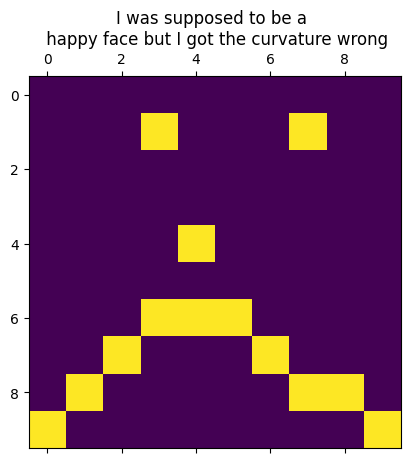

This is the binary representation of the tree
0001111000000111100000001100000000110000001111111000001100100000110000000011000000001100000000110000


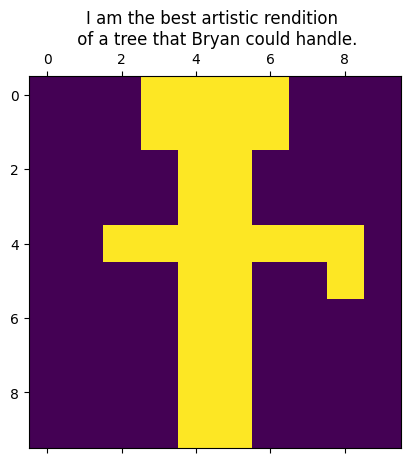

In [1]:
from dataclasses import dataclass, field
import numpy as np
import matplotlib.pyplot as plt
import makeImage

**Building the Network**

In [ ]:
@dataclass
class HopfieldNetwork:
    states: np.ndarray
    biases: np.ndarray
    weights: np.ndarray
    energy_snapshots: list = field(default_factory=list)
    neurons: int = 0

    @classmethod
    def build(network, N):

        states = np.random.choice([-1, 1], size=N)

        biases = np.random.uniform(-1, 1, size=N)

        W = np.random.uniform(-1, 1, size=(N, N))
        W = np.triu(W, k=1)
        W = W + W.T

        neurons = N

        return network(states=states, biases=biases, weights=W, neurons=neurons)
    
    def update(self):
        i = np.random.randint(len(self.states))
        incoming = self.weights[i] @ self.states
        self.states[i] = 1 if incoming > self.biases[i] else -1

    def next_state(self, neuron, state):
        incoming = self.weights[neuron] @ state
        new = state.copy()
        new[neuron] = 1 if incoming > self.biases[neuron] else -1
        return new

    def is_converged(self):
        #If all neurons are same when updated, then converged
        wanted = np.where(self.weights @ self.states > self.biases, 1, -1)
        return np.array_equal(wanted, self.states)

    def total_energy(self):
        weighted_energy = -.5 * self.states @ self.weights @ self.states
        bias_energy = self.biases @ self.states
        return weighted_energy + bias_energy

    def store_energy_snapshot(self):
        self.energy_snapshots.append(self.total_energy())

    def memorize(self, memory: np.array):

        mem = np.asarray(memory)

        if mem.ndim == 1:
            mem = mem.reshape(-1, 1)

        m = mem.shape[1]
        W = (mem @ mem.T) / m
        np.fill_diagonal(W, 0)
        
        self.weights = W
        self.biases = np.zeros(mem.shape[0])

    def run_until_converge(self, input_state=None, max_sweeps=1000,
                           preserve_state=False, record_energy=True):
        original = self.states.copy()

        if input_state is not None:
            self.states = np.array(input_state, dtype=int).flatten()

        self.energy_snapshots.clear()
        
        if record_energy:
            self.store_energy_snapshot()

        sweeps = 0
        while not self.is_converged() and sweeps < max_sweeps:
            for _ in range(self.neurons):
                self.update()
            if record_energy:
                self.store_energy_snapshot()
            sweeps += 1

        result = self.states.copy()

        if preserve_state:
            self.states = original

        return result

    def show_state(self, title=None):
        side = int(np.sqrt(len(self.states)))
        plt.matshow(self.states.reshape(side, side))
        if title:
            plt.title(title)
        plt.show()

    def int_to_state(self, x):
        bits = (x >> np.arange(self.neurons)) & 1
        return 2 * bits - 1
    
    def state_to_int(self, s):
        bits = (s + 1) // 2
        return int(np.sum(bits << np.arange(self.neurons)))
    
    def Get_Energy_Landscape(self, memories, filename="landscape.digraph"):
        
        memory_ids = [self.state_to_int(memories[:, k]) for k in range(memories.shape[1])]
    
        with open(filename, "w") as f:
            f.write("digraph G {\n")
            for mid in memory_ids:
                f.write(f"  {mid} [style=filled, fillcolor=red];\n")
    
            for x in range(2 ** self.neurons):
                state = self.int_to_state(x)
                for neuron in range(self.neurons):
                    new = self.next_state(neuron, state)
                    if not np.array_equal(new, state):
                        f.write(f"  {x} -> {self.state_to_int(new)};\n")
    
            f.write("}\n")
        




network = HopfieldNetwork.build(N=5)


**Energy going down during a run**

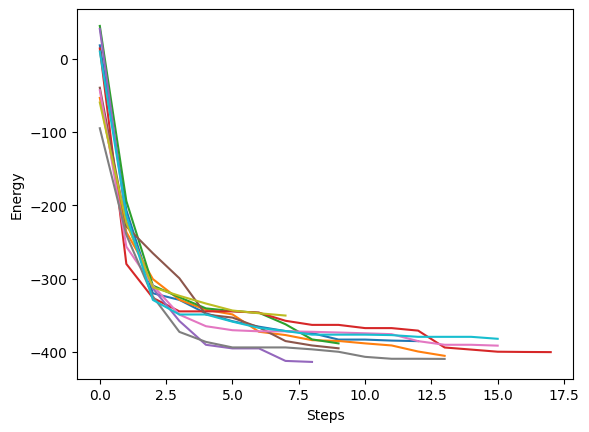

In [13]:
networks = []

N = 100

for i in range(10):

    new_network = HopfieldNetwork.build(N) #100 neurons
    new_network.run_until_converge()
    networks.append(new_network)

plt.figure()
for net in networks:
    plt.plot(net.energy_snapshots)
plt.xlabel("Steps")
plt.ylabel("Energy")
plt.show()

**Training Inputs**

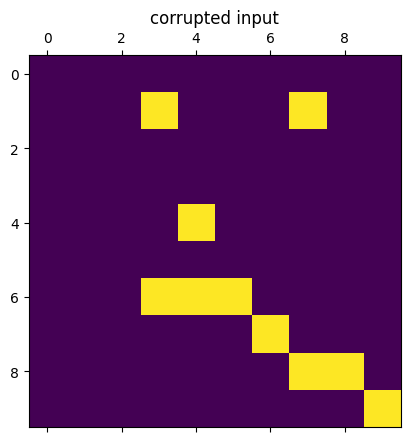

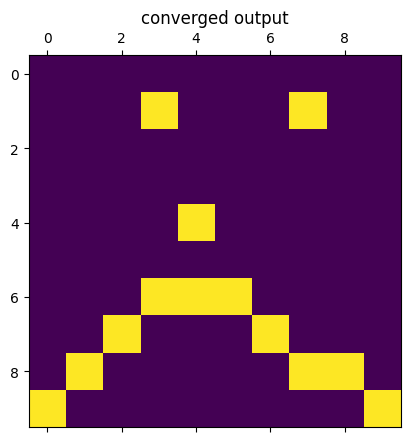

overlap with face: 100


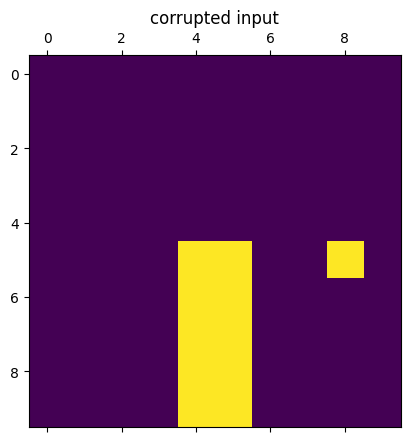

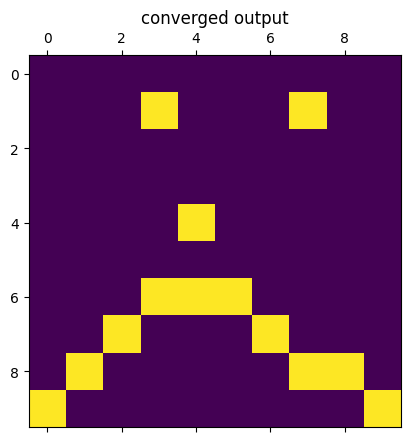

overlap with tree: 30


In [14]:
face = np.asarray(makeImage.MakeFace()).astype(int).flatten()
face[face == 0] = -1

tree = np.asarray(makeImage.MakeTree()).astype(int).flatten()
tree[tree == 0] = -1

N = face.size
side = int(np.sqrt(N))

network = HopfieldNetwork.build(N)
memory = np.column_stack((face, tree))

network.memorize(memory)

img = face.reshape(side, side).copy()
cols = int(np.ceil(side / 4))
img[:, :cols] = -1

network.states = img.flatten()
network.show_state("corrupted input")

network.run_until_converge()
network.show_state("converged output")

print("overlap with face:", network.states @ face)

network = HopfieldNetwork.build(N)
memory = np.column_stack((face, tree))

network.memorize(memory)

tree_img = tree.reshape(side, side).copy()
tree_img[:side // 2, :] = -1

network.states = tree_img.flatten()
network.show_state("corrupted input")

network.run_until_converge()
network.show_state("converged output")

print("overlap with tree:", network.states @ tree)

**Number of Memories**

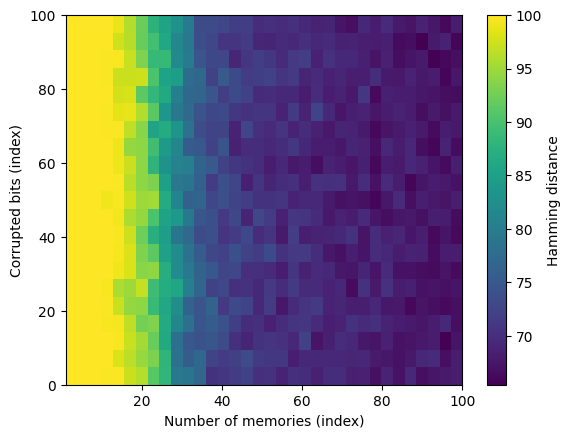

In [16]:
NEURONS = 100

def corrupt(v, k):
    out = v.copy()
    idx = np.arange(len(v))
    np.random.shuffle(idx)
    out[idx] *= -1
    return out

def avg_distance(p, k, n_sets=5, n_attempts=20):
    network = HopfieldNetwork.build(NEURONS)
    dists = []
    for _ in range(n_sets):
        memories = np.random.choice([-1, 1], size=(NEURONS, p))
        network.memorize(memories)
        for _ in range(n_attempts):
            target = memories[:, np.random.randint(p)]
            result = network.run_until_converge(corrupt(target, k), record_energy=False)
            dists.append(np.sum(result != target))
    return np.mean(dists)


p_values = range(1, 101, 3)
k_values = range(0, 101, 5)
grid = np.array([[avg_distance(p, k) for p in p_values] for k in k_values])
plt.imshow(grid, origin="lower", aspect="auto", extent=[p_values[0], p_values[-1], k_values[0], k_values[-1]])
plt.colorbar(label="Hamming distance")
plt.xlabel("Number of memories (index)")
plt.ylabel("Corrupted bits (index)")
plt.show()

**Energy Landscapes**

In [21]:
NEURONS = 6
network = HopfieldNetwork.build(NEURONS)
memories = np.random.choice([-1, 1], size=(NEURONS, 2))
network.memorize(memories)
network.Get_Energy_Landscape(memories)

**Diffusion**

Approach 1

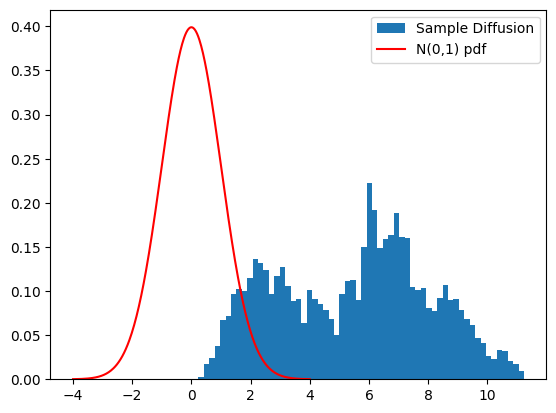

In [ ]:
## Consider pollen particle, buffeted by air, it keeps going random directions

## At time t particle is at x(t) = x(t-1) + sqrt(delta)z where z is random gaussian random number

## If it were in some kind of potential field E(x)

## Langevin Equation: x(t) = x(t - 1) + delta/2 * F(x(t-1)) + sqrt(delta)z

## F is equal to e^(-E(x(t-1)))

# Since this is a markov chain, new position only depends on the current position.
# Will lead to a stationary dist

# You will end up with a probability distribution of e^(-E(x))

@dataclass
class Diffuser:

    def simple_oscillator_Energy(x):
        return x**2 / 2

    def ForwardDiffusion(x_0,T, delta, oscillator):
        locations = []
        locations.append(x_0)

        for _ in range(T):

            z = np.random.randn()

            Energy = oscillator(locations[-1])

            F_ = np.exp(-Energy)

            new_location = locations[-1] + (delta/2) * F_ + np.sqrt(delta) * z

            locations.append(new_location)

        return locations

    def Metropolis(x_0, T, delta, oscillator):
        locations = []
        locations.append(x_0)
    
        for _ in range(T):
            x = locations[-1]
            new = x + np.sqrt(delta) * np.random.randn()
    
            A = np.exp(-(oscillator(new) - oscillator(x)))
    
            if np.random.rand() < A:
                locations.append(new)
            else:
                locations.append(x)
    
        return locations

    


T = 10_000
x_0 = 1
delta = .01
diffused = Diffuser.ForwardDiffusion(1, T, delta, Diffuser.simple_oscillator_Energy)[1000:]
plt.hist(diffused, bins=60, density=True, label="Sample Diffusion")

xs = np.linspace(-4, 4, 400)

plt.plot(xs, np.exp(-xs**2 / 2) / np.sqrt(2*np.pi), "r-", label="N(0,1) pdf")
plt.legend()
plt.show()


Approach 2

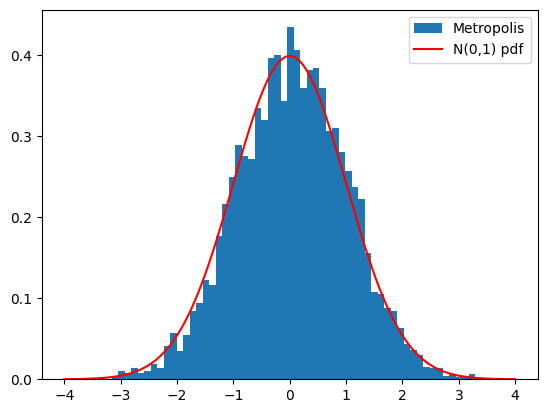

In [ ]:
## Metropolis: propose x' from T(x -> x'), accept with A = pi(x')/pi(x) * T(x' -> x)/T(x -> x')
## pi(x) = e^(-E(x))

T = 10_000
delta = .5
metro = Diffuser.Metropolis(1, T, delta, Diffuser.simple_oscillator_Energy)[1000:]

plt.hist(metro, bins=60, density=True, label="Metropolis")
xs = np.linspace(-4, 4, 400)
plt.plot(xs, np.exp(-xs**2 / 2) / np.sqrt(2*np.pi), "r-", label="N(0,1) pdf")
plt.legend()
plt.show()

Approach 3